# Analysis Pipeline

In this notebook we analyse the quality of the ScArches mapping using the *MappingAccessment* package. 

### Library Imports

In [1]:
# os.chdir('../')
import warnings
import os
from os.path import abspath

import scanpy as sc
import anndata
import matplotlib.pyplot as plt
import numpy as np

import pandas as pd
import datetime
import statsmodels.stats.multitest as mtc
from MappingAssessment import MapAnalyzer, Plotter


### General settings

In [2]:
warnings.simplefilter(action="ignore", category=FutureWarning)
warnings.simplefilter(action="ignore", category=UserWarning)

DATA_DIR = abspath(os.path.join(os.getcwd(), os.pardir, 'data'))
os.makedirs('Results', exist_ok=True)
RESULTS_DIR = os.path.join(os.getcwd(), 'Results')

In [3]:
#set parameters here
dataset = "Meyer_2021_5_prime"
ident = "Meyer_2021_5_prime"
query_color = "Blue"
condition = "X"
exclude = []

In [4]:
adata = sc.read(f'{DATA_DIR}/HLCA_full_v1.1_emb.h5ad')

In [5]:
adata

AnnData object with n_obs × n_vars = 2282447 × 30
    obs: 'suspension_type', 'donor_id', 'is_primary_data', 'assay_ontology_term_id', 'cell_type_ontology_term_id', 'development_stage_ontology_term_id', 'disease_ontology_term_id', 'self_reported_ethnicity_ontology_term_id', 'tissue_ontology_term_id', 'organism_ontology_term_id', 'sex_ontology_term_id', "3'_or_5'", 'BMI', 'age_or_mean_of_age_range', 'age_range', 'anatomical_region_ccf_score', 'ann_coarse_for_GWAS_and_modeling', 'ann_finest_level', 'ann_level_1', 'ann_level_2', 'ann_level_3', 'ann_level_4', 'ann_level_5', 'cause_of_death', 'core_or_extension', 'dataset', 'fresh_or_frozen', 'log10_total_counts', 'lung_condition', 'mixed_ancestry', 'original_ann_level_1', 'original_ann_level_2', 'original_ann_level_3', 'original_ann_level_4', 'original_ann_level_5', 'original_ann_nonharmonized', 'reannotation_type', 'sample', 'scanvi_label', 'sequencing_platform', 'smoking_status', 'study', 'subject_type', 'tissue_coarse_unharmonized', 'ti

In [6]:
adata = adata[(adata.obs.core_or_extension=="core")|((adata.obs.dataset==dataset))]

### Preprocessing

Set clean cell labels on all levels and one label-column for transfer from curated metadata, assumed to be done in the package 

In [8]:
# In case that no umap based on the embedding is calculated, recalculate the UMAP
# sc.pp.neighbors(adata, n_neighbors=50, n_pcs=30)
# sc.tl.umap(adata)

Reload module for changes to take effect

In [7]:
# import imp

# imp.reload(MapAnalyzer)

Initialize *AdataHandler* object. The *AdataHandler* makes sure all columns are named a standarized way. It also is able to perform a label transfer to the query.

In [8]:
adata_handler = MapAnalyzer.AdataHandler(
    adata,
    workspace= RESULTS_DIR,
    ident=ident + "/",  # folder that indentifies this workpartition
    log = True,  # create a logfile
)

Logger directory already exists


In [9]:
# Plotter object for the plots
plotter = Plotter.MapPlot(workspace=f"{adata_handler.workspace}/{ident}")

In [10]:
adata_handler.standarize_columns(
    condition_name=condition,  # condition name we want to distinguish
    query_dataset=dataset,  # query datasets
    cell_type_col=None,  # column name denoting celltype, none if no unified column
    dataset_col="dataset",  # column name denoting dataset
    sample_col="sample",  # column name danoting sample
    condition_col="lung_condition",  # column name denoting condition (abovementioned)
    subject_col="donor_id",  # column name denoting patients, subjects or donors
    disease_exclude=exclude,  # diseases to exclude from analysis
)

2023-06-08 07:49:31.963090	Standarizing columns...
2023-06-08 07:49:34.423561	No cell_type column set. Please make sure to run 'set_cell_type_levels' to obtain a unified cell type column 'cell_label'.
2023-06-08 07:49:34.425550	Finished column standarizing



Set appropriate levels for the cell type annotation

In [11]:
adata_handler.set_cell_type_levels(
    connect_threshold = 1, 
    annotation_columns = ['ann_level_1', 'ann_level_2', 'ann_level_3', 'ann_level_4', 'ann_level_5'],
    finest_level_column = "ann_finest_level",
    unlabeled_tag = "nan")

2023-06-08 07:49:42.234441	starting with cell labels:
['AT0', 'AT1', 'AT2', 'AT2 proliferating', 'Adventitial fibroblasts', 'Alveolar Mph CCL3+', 'Alveolar Mph MT-positive', 'Alveolar Mph proliferating', 'Alveolar fibroblasts', 'Alveolar macrophages', 'B cells', 'Basal resting', 'CD4 T cells', 'CD8 T cells', 'Classical monocytes', 'Club (nasal)', 'Club (non-nasal)', 'DC1', 'DC2', 'Deuterosomal', 'EC aerocyte capillary', 'EC arterial', 'EC general capillary', 'EC venous pulmonary', 'EC venous systemic', 'Goblet (bronchial)', 'Goblet (nasal)', 'Goblet (subsegmental)', 'Hematopoietic stem cells', 'Hillock-like', 'Interstitial Mph perivascular', 'Ionocyte', 'Lymphatic EC differentiating', 'Lymphatic EC mature', 'Lymphatic EC proliferating', 'Mast cells', 'Mesothelium', 'Migratory DCs', 'Monocyte-derived Mph', 'Multiciliated (nasal)', 'Multiciliated (non-nasal)', 'Myofibroblasts', 'NK cells', 'Neuroendocrine', 'Non-classical monocytes', 'Peribronchial fibroblasts', 'Pericytes', 'Plasma cell

In [12]:
adata = adata_handler.get_adata()

Transfer celltype labels from reference data to query cells

In [13]:
adata_handler.transfer_labels(transfer_columns=["cell_label"],pickle=False)

2023-06-08 07:52:17.040149	Transferring labels...
2023-06-08 07:52:18.069473	Train KNNModel
Weighted KNN with n_neighbors = 50 ... 2023-06-08 07:52:18.323314	transferring cell_label


ValueError: Found array with 0 sample(s) (shape=(0, 30)) while a minimum of 1 is required by KNeighborsTransformer.

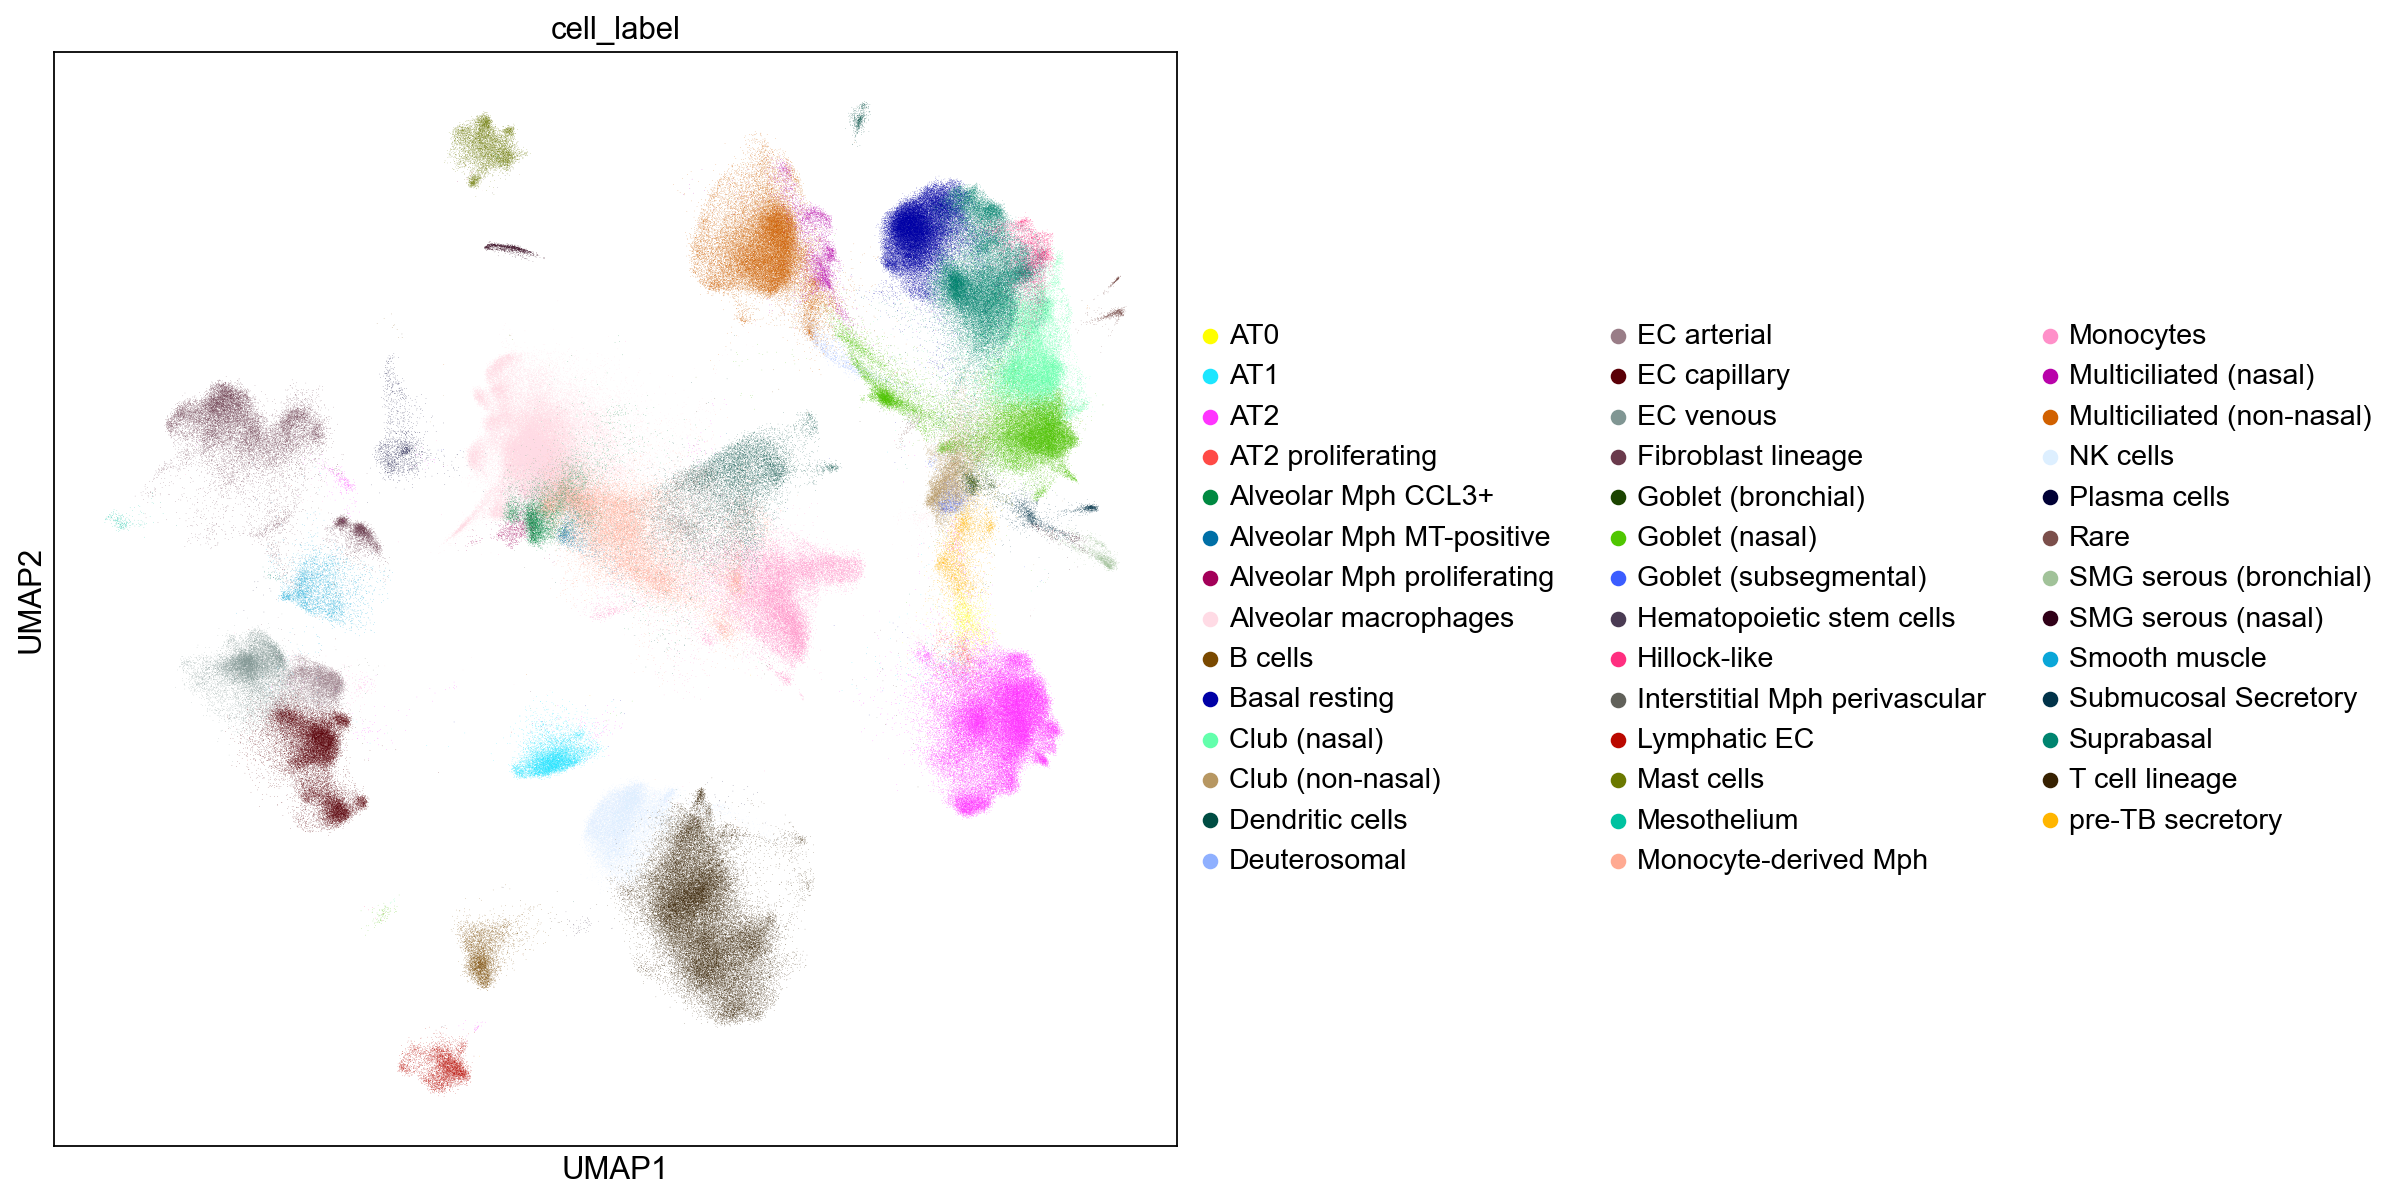

In [14]:
sc.pl.umap(adata,color="cell_label")

In [15]:
adata.obs[["query_or_reference","cell_label"]]

,query_or_reference,cell_label
CGATGTAAGTTACGGG_SC10,reference,Alveolar macrophages
ATTCTACCAAGGTTCT_HD68,reference,EC capillary
P1_2_TGCTGCTAGCTCCTCT,reference,Alveolar macrophages
CTGATAGTCTTAGAGC_F01367,reference,EC arterial
D344_Brus_Dis1_CATTCGCGTGCCTGCA-1-14,reference,Club (non-nasal)
...,...,...
ACACCAACAAGACAC_GRO-03_biopsy,reference,EC capillary
AGTGGGAGTTGTCTTT-1-7,reference,Goblet (nasal)
P3_4_TAAACCGGTGTCCTCT,reference,Fibroblast lineage
P3_4_GCTTGAACACGACGAA,reference,Fibroblast lineage


In [16]:
adata.obs.query_or_reference.cat.categories

Index(['reference'], dtype='object')

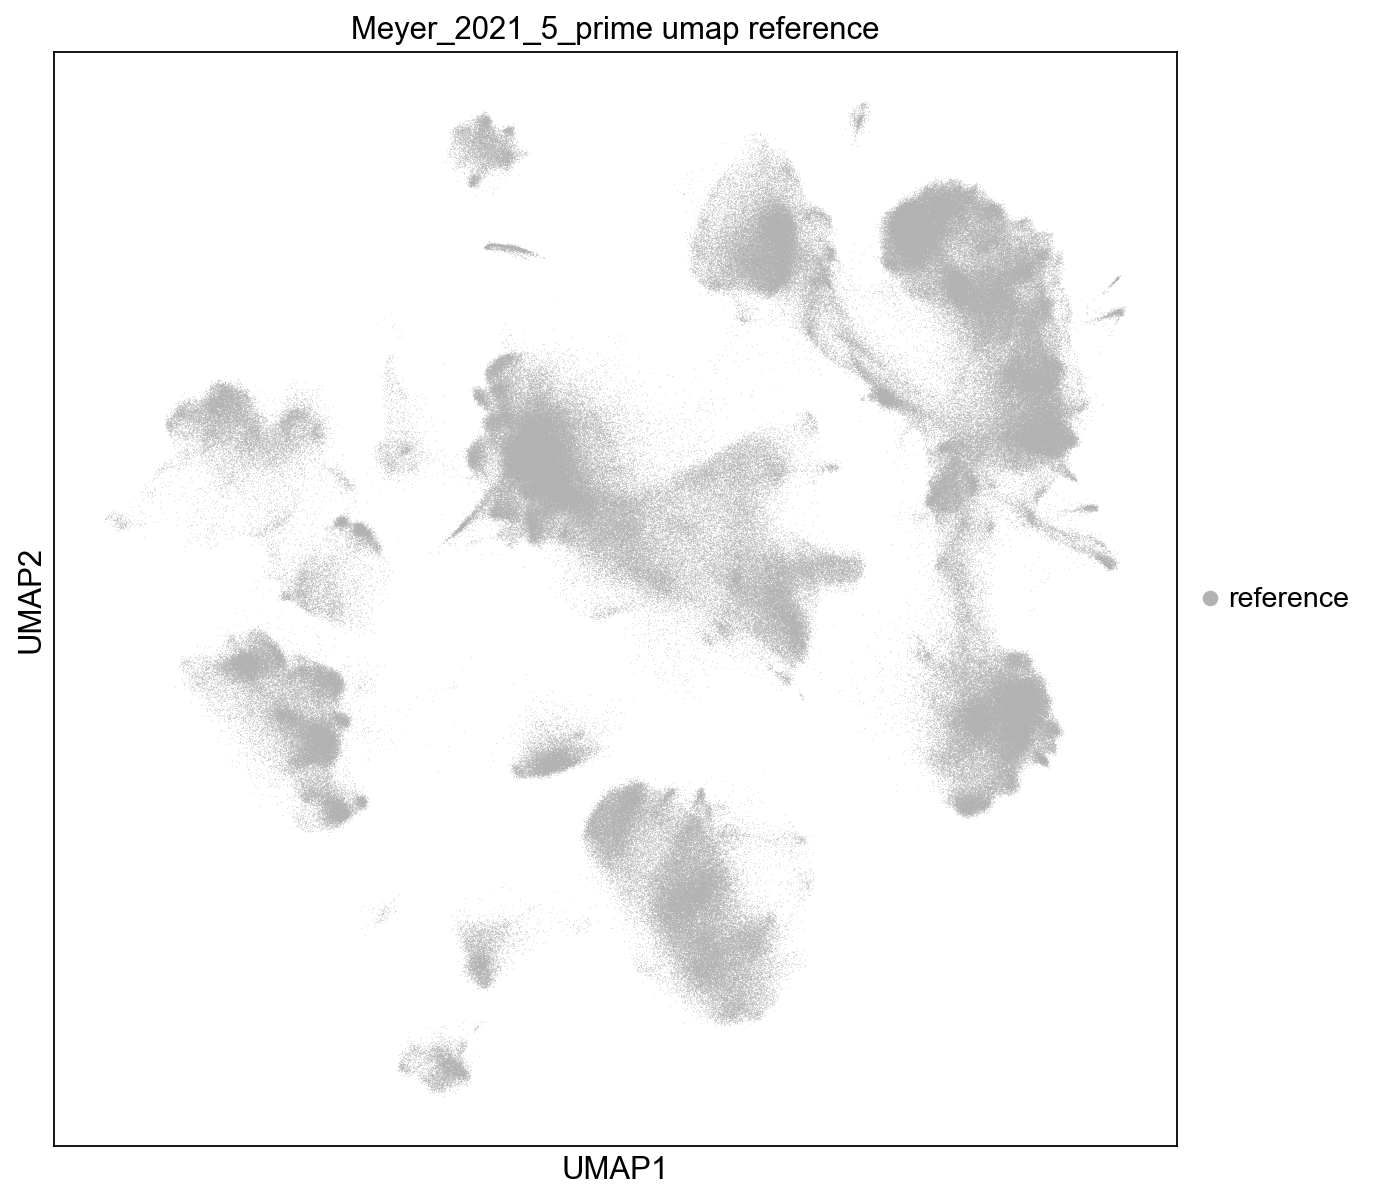

In [17]:
plotter.plot_umap(
    adata=adata, color_query=query_color, title_stub=ident, mode="reference", save=False
)

### Main Pipeline

Initialize the *MappingScoring* object. Pass the *AdataHandler* so that adata and workspace information is passed on.

In [18]:
scorer = MapAnalyzer.MappingScoring(adata_handler)

Logger directory already exists


In [19]:
adata = scorer.get_adata()

#### Calculate or pass query mixing scores

In [20]:
'''scorer.calculate_mixing_scores(
    n_neighbors=15,
    min_subjects=40,
    samples=None,
    reinitialize=True,
    embedding="X",
    verbose=True,
    overwrite=True,
    save=True,
)'''

'scorer.calculate_mixing_scores(\n    n_neighbors=15,\n    min_subjects=40,\n    samples=None,\n    reinitialize=True,\n    embedding="X",\n    verbose=True,\n    overwrite=True,\n    save=True,\n)'

In [21]:
scorer.add_scores(
    os.path.join(scorer.workspace, ident, 'scores.csv')
)

FileNotFoundError: [Errno 2] No such file or directory: '/Users/apple/Dropbox/My Mac (MacBook Air di apple)/Desktop/Projects/Theis lab/HiWi/Lisa/atlas_extension/05_MapQC/Results/Meyer_2021_5_prime/scores.csv'

**Baseline calculation:**  
To compare our mapping to a upper bound, we calculate the scores for the integrated reference. For that we set one sample to query, while the other samples are set to reference (excluding the real query). By that we achieve a baseline for each celltype of how well different samples are integrated. We then can compare out mapping scores to the baseline to see, wether the mapping is of comparable quality to the integration. 

In [22]:
scorer.add_baseline(
    os.path.join(scorer.workspace, 'baseline.csv'),
    os.path.join(RESULTS_DIR, 'MapAnalyzer_Results_3.0', 'celltypes.txt')
)

FileNotFoundError: [Errno 2] No such file or directory: '/Users/apple/Dropbox/My Mac (MacBook Air di apple)/Desktop/Projects/Theis lab/HiWi/Lisa/atlas_extension/05_MapQC/Results/baseline.csv'

add correction model for score correction for sample size:

In [23]:
scorer.add_transformation(os.path.join(RESULTS_DIR, 'MapAnalyzer_Results_3.0', 'transformation.csv'))

FileNotFoundError: [Errno 2] No such file or directory: '/Users/apple/Dropbox/My Mac (MacBook Air di apple)/Desktop/Projects/Theis lab/HiWi/Lisa/atlas_extension/05_MapQC/Results/MapAnalyzer_Results_3.0/transformation.csv'

### Analyzing the Mapping with MapAnalyzer

In [24]:
adata = scorer.get_adata()

In [25]:
scorer.analyze_mapping()

Exception: You need to add or calculate the baseline first

In [26]:
scorer.sample_report

AttributeError: 'MappingScoring' object has no attribute 'sample_report'

In [27]:
scorer.report.to_csv(
    os.path.join(RESULTS_DIR, 'MapAnalyzer_Results_3.0', 'report.csv')
)

AttributeError: 'MappingScoring' object has no attribute 'report'

### Plotting the outcomes

In [28]:
report = scorer.report.loc

AttributeError: 'MappingScoring' object has no attribute 'report'

In [29]:
adata = adata[adata.obs.cell_label.isin(scorer.cell_types)]

AttributeError: 'MappingScoring' object has no attribute 'cell_types'

In [30]:
adata

AnnData object with n_obs × n_vars = 584944 × 30
    obs: 'suspension_type', 'subject_ID', 'is_primary_data', 'assay_ontology_term_id', 'cell_type_ontology_term_id', 'development_stage_ontology_term_id', 'disease_ontology_term_id', 'self_reported_ethnicity_ontology_term_id', 'tissue_ontology_term_id', 'organism_ontology_term_id', 'sex_ontology_term_id', "3'_or_5'", 'BMI', 'age_or_mean_of_age_range', 'age_range', 'anatomical_region_ccf_score', 'ann_coarse_for_GWAS_and_modeling', 'ann_finest_level', 'ann_level_1', 'ann_level_2', 'ann_level_3', 'ann_level_4', 'ann_level_5', 'cause_of_death', 'core_or_extension', 'dataset', 'fresh_or_frozen', 'log10_total_counts', 'lung_condition', 'mixed_ancestry', 'original_ann_level_1', 'original_ann_level_2', 'original_ann_level_3', 'original_ann_level_4', 'original_ann_level_5', 'original_ann_nonharmonized', 'reannotation_type', 'sample', 'scanvi_label', 'sequencing_platform', 'smoking_status', 'study', 'subject_type', 'tissue_coarse_unharmonized', 't

In [31]:
plotter.plot_baseline_comparison(
    adata,
    query_color,
    ident,
    disease=True,
    save=True,
    violin=True,
    #sample_filter=report,
    transform = os.path.join(RESULTS_DIR, 'MapAnalyzer_Results_3.0', 'transformation.csv')
)

KeyError: "Column(s) ['score'] do not exist"

In [32]:
def group_adata(adata):
    group_adata = (
        adata.obs.groupby(["cell_label", "sample"])
        .agg({"score": "mean", "dataset": "first", "subject_ID": "count"})
        .dropna()
        .reset_index(drop=False)
    )

    group_adata["cell_label"] = group_adata["cell_label"].cat.remove_unused_categories()
    group_adata = group_adata.rename(columns={"subject_ID": "count"})
    group_adata["log_count"] = np.log(group_adata["count"])
    return group_adata